In [61]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

In [46]:

def rk4(fun,tempos,y0):

    '''
    Resolve uma Equação Diferencial Ordinária (EDO) usando o método RK4.

    Implementa o método clássico de Runge-Kutta de quarta ordem para aproximar a
    solução de um Problema de Valor Inicial (PVI) da forma dy/dt = f(t, y), com
    condição inicial y(t0) = y0, utilizando um passo fixo h.
    
    '''

    y = [y0]
    dt = tempos[1] - tempos[0]

    for t in tempos[:-1]:

        k1 = fun(t, y[-1])
        k2 = fun(t + dt/2, y[-1] + k1*dt/2)
        k3 = fun(t + dt/2, y[-1] + k2*dt/2)
        k4 = fun(t + dt , y[-1] + dt*k3)

        y.append(y[-1] + dt/6 * (k1 + 2*k2 + 2*k3 + k4))

    return np.array(y)



In [ ]:
def aceleracoes(y, g  = 9.8 , l = 1.0):
        
    theta1 , theta2 , w1 , w2 = y
    delta = theta1 - theta2
    den = 16 - 9 * np.cos(delta) ** 2
    a1 = -3*(2*w2**2*np.sin(delta) + 3*np.cos(delta)*w1**2*np.sin(delta) + 6*(g/l)*np.sin(theta1) - 3*np.cos(delta)*(g/l)*np.sin(theta2)) / den
    a2 =  3*(8*w1**2*np.sin(delta) + 3*np.cos(delta)*w2**2*np.sin(delta) - 8*(g/l)*np.sin(theta2) + 9*np.cos(delta)*(g/l)*np.sin(theta1)) / den
    
    return a1,a2

In [48]:
def derivadas(y , g = 9.8 , l = 1.0):
    a1 , a2 = aceleracoes(y, g = 9.8 , l = 1.0)
    return np.array([y[2] , y[3] , a1 , a2])        # [ω1, ω2, θ̈1, θ̈2]

In [49]:
def energia(y, m = 1.0 , g = 9.8 , l = 1.0):
    th1, th2, w1, w2 = y
    T = m*l**2/6 * (4*w1**2 + w2**2 + 3*w1*w2*np.cos(th1 - th2))
    U = -0.5*m*g*l * (3*np.cos(th1) + np.cos(th2))
    return T + U

In [50]:
g = 9.8
l = 1.0

fun = lambda t , y: derivadas(y,g,l)

In [55]:
tempos = np.arange(0 , 20 , 0.001)
y0 = np.array([np.pi/2, np.pi/2, 0.0, 0.0])
Y = rk4(fun , tempos , y0)

In [56]:
Es = np.array([energia(y) for y in Y])
print("deriva máxima da energia:", np.max(np.abs(Es - Es[0])))

deriva máxima da energia: 1.4470077878248333e-07


In [57]:
x2 = l*np.sin(Y[:, 0]) + l*np.sin(Y[:, 1])
y2 = -l*np.cos(Y[:, 0]) - l*np.cos(Y[:, 1])

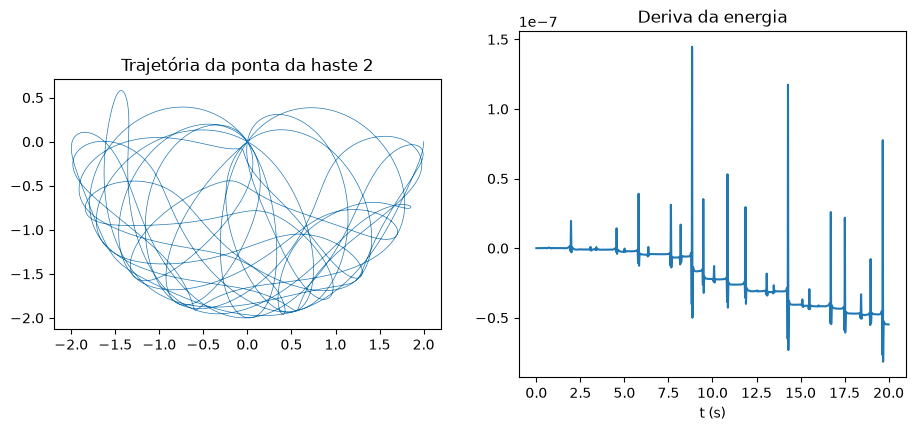

In [85]:

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

ax[0].plot(x2, y2, lw=0.5)
ax[0].set_aspect("equal")
ax[0].set_title("Trajetória da ponta da haste 2")
ax[1].plot(tempos, Es - Es[0])
ax[1].set_title("Deriva da energia")
ax[1].set_xlabel("t (s)")

plt.show()